In [21]:
import illustris_python as il
import numpy as np
import matplotlib.pylab as plt
import os
import h5py
from scipy.stats import binned_statistic
from scipy.stats import binned_statistic_2d
from matplotlib.colors import LogNorm
from numpy import linalg as LA 

# Paths to the IllustrisTNG catalogues

basePath_TNG50 = '/home/tnguser/sims.TNG/TNG50-1/output/'

SubhaloIDs = 3 #Subhalo ID

#snapshot and redshift we will use
snap = 99
red = 0.0
h = 0.6774

In [22]:
subhalo_stars = il.snapshot.loadSubhalo(basePath_TNG50, snap, SubhaloIDs, 'stars', fields=['GFM_Metals','Masses'])

# also load some metadata from this snapshot from the 'header'
#header = il.groupcat.loadHeader(basePath_TNG50_4, snap)

In [23]:
subhalo_stars['count']

1645757

In [24]:
o = subhalo_stars['GFM_Metals'][:,4]
fe = subhalo_stars['GFM_Metals'][:,8]
mg = subhalo_stars['GFM_Metals'][:,6]
h = subhalo_stars['GFM_Metals'][:,0]
si = subhalo_stars['GFM_Metals'][:,7]
ne = subhalo_stars['GFM_Metals'][:,5]

In [25]:
mgfe =  np.log10( ((mg*56))/(fe*24)) +0.09
feh =  np.log10(fe/(h*56)) + 4.5

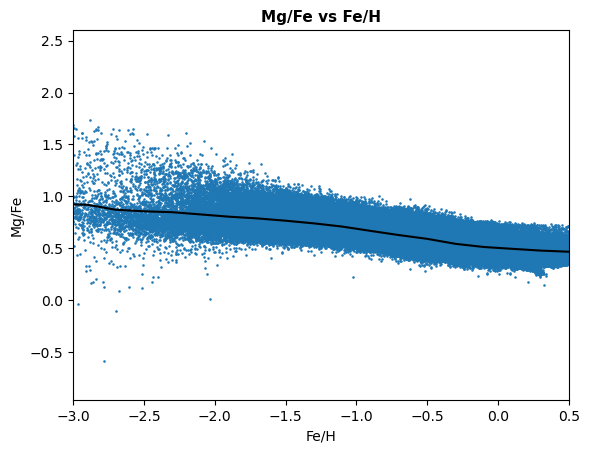

In [26]:
plt.scatter((feh),(mgfe), s = 0.7)
plt.title('Mg/Fe vs Fe/H', fontsize=11, fontweight='bold')
plt.xlim(-3,0.5)
#plt.ylim(0,1.3)

plt.ylabel('Mg/Fe')
plt.xlabel('Fe/H')

# Compute mean values in bins of 0.5 dex
bin_width = 0.2
bins = np.arange(-10, 5. + bin_width, bin_width)
bin_means, bin_edges, _ = binned_statistic(feh, mgfe, statistic='mean', bins=bins)

# Plot the mean values
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
plt.plot(bin_centers, bin_means, color='black',  label='Mean Values')
plt.savefig('/home/tnguser/Lucas/images/TNG50-1_MgFeVsFeH')

In [27]:
sife =  np.log10( ((si*56))/(fe*28)) + 0.05
feh =  np.log10(fe/(h*56)) + 4.5

In [ ]:
plt.scatter((feh),(sife), s = 0.7)
plt.title('Si/Fe vs Fe/H', fontsize=11, fontweight='bold')
plt.xlim(-3,0.5)
plt.ylim(0,1.3)

plt.ylabel('Mg/Fe')
plt.xlabel('Fe/H')


# Compute mean values in bins of 0.5 dex
bin_width = 0.2
bins = np.arange(-10, 5. + bin_width, bin_width)
bin_means, bin_edges, _ = binned_statistic(feh, sife, statistic='mean', bins=bins)

# Plot the mean values
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
plt.plot(bin_centers, bin_means, color='black',  label='Mean Values')
plt.savefig('/home/tnguser/Lucas/images/TNG50-1_SiFeVsFeH')

In [ ]:
alphafe =  np.log10( ( (mg*56) + si*56   ) / (fe*24*28*2) )   + 0.09 + 0.05
feh =  np.log10(fe/(h*56)) + 4.5

In [ ]:
#alphafe =  np.log10( ( (mg*56) + si*56   ) / (fe*24*28*3) )   + 0.09 + 0.05 
#feh =  np.log10(fe/(h*56)) + 4.5

In [ ]:
plt.scatter((feh),(alphafe), s = 0.7)
plt.title('Alpha/Fe vs Fe/H', fontsize=11, fontweight='bold')
plt.xlim(-3,0.5)
#plt.ylim(0,1.3)

plt.ylabel('Mg/Fe')
plt.xlabel('Fe/H')


# Compute mean values in bins of 0.5 dex
bin_width = 0.2
bins = np.arange(-3,1. + bin_width, bin_width)
bin_means, bin_edges, _ = binned_statistic(feh, alphafe, statistic='mean', bins=bins)

# Plot the mean values
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
plt.plot(bin_centers, bin_means, color='black',  label='Mean Values')
plt.savefig('/home/tnguser/Lucas/images/TNG50-1_AlphaFeVsFeH')